# Figure 2: library quality, read assignment and host quantification

Run **Restart Kernel and Run All** from the release root or `figures/`. This notebook is self-contained apart from NumPy, pandas and Matplotlib. Each panel prepares and previews its data; the last cell exports a 180 mm wide PDF, a 600 dpi PNG, and full-precision TSV source tables to `figures/output/fig2/`. The revised layout retains the real-input definitions used by `05_analysis/Figure2_full_from_multiqc.py`.

| Panel | Packaged input | Analysis source and metric |
|---|---|---|
| a, b | `input_data/fig2ab.multiqc_data.json` | Saved fastp records in MultiQC 1.35: raw/retained read pairs; after-filtering Q30 and GC, reported duplication, adapter-trimmed raw reads. |
| c | `input_data/fig2c.assignment_real.tsv` | `05_analysis/Fig2c_assignment_REAL.tsv`, derived from HISAT2 pair counts and mapping composition. Five exclusive categories divided by non-rRNA input pairs. Raw mapping/HISAT2 tables are packaged for checks. |
| d | `input_data/fig2d.host_assignment_real.tsv`, panel c | `05_analysis/Fig2d_host_assignment_REAL.tsv`: featureCounts Assigned fragments and potato genes with TPM > 1. Assignment percentage divides Assigned fragments by uniquely assigned potato nuclear read pairs from panel c. Three replicates are summarized horizontally by sampling time. |
| all | `../data_records/1. sample_metadata.txt` | The same 27-library order, time and replicate. |

No simulated records or QC review thresholds are used. The release workflow config resolves `output_dir ../../04_results` relative to `workflow/`; this notebook uses the packaged real inputs. Figure text is Arial (6 pt), with editable TrueType text in PDF. All explicitly specified colours are drawn from the Figure 3 palette or its neutral guide colours. Time is shown by horizontal position in panels a–c and by rows in panel d. The [Nature figure guide](https://research-figure-guide.nature.com/figures/building-and-exporting-figure-panels/) informs export and panel assembly.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def locate_figures():
    for candidate in (Path.cwd(), Path.cwd() / "figures"):
        if (candidate/"input_data").is_dir() and (candidate.parent/"data_records"/"1. sample_metadata.txt").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Start from the release root or figures directory")

FIGURES = locate_figures()
INPUT = FIGURES/"input_data"
metadata = pd.read_csv(FIGURES.parent/"data_records"/"1. sample_metadata.txt",sep="\t",usecols=["sample_id","time_h","biological_replicate","treatment"])
if len(metadata)!=27 or metadata.sample_id.duplicated().any():
    raise ValueError("Expected 27 unique metadata samples")
metadata = metadata.sort_values(["time_h","biological_replicate"]).reset_index(drop=True)
SAMPLES = metadata.sample_id.tolist()
metadata["label"] = metadata.apply(lambda r: f"Mock-{int(r.biological_replicate)}" if int(r.time_h)==0 else f"{int(r.time_h)}hpi-{int(r.biological_replicate)}",axis=1)

def align_samples(data):
    if data.sample_id.duplicated().any() or set(data.sample_id)!=set(SAMPLES):
        raise ValueError("Sample IDs disagree with metadata")
    return metadata.merge(data,on="sample_id",validate="one_to_one").sort_values(["time_h","biological_replicate"]).reset_index(drop=True)

STYLE={"font_size":6,"tick_size":6,"title_size":6,"png_dpi":600}
plt.rcParams.update({"font.family":"Arial","font.size":STYLE["font_size"],"pdf.fonttype":42})
print(f"Input: {FIGURES}; samples: {len(SAMPLES)}")

ANALYSIS={"fastp_reads_per_pair":2,"mapping_denominator":"input_non_rrna_pairs"}
STYLE.update({"figure_size":(180/25.4,120/25.4)})

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator

def time_geometry(data):
    counts=data.groupby("time_h",sort=True).size().tolist()
    ends=np.cumsum(counts)
    centers=ends-(np.array(counts)-1)/2
    return centers.tolist(),(ends[:-1]+0.5).tolist(),sorted(data.time_h.unique().tolist())

def padded_limits(values,lower_zero=False):
    low=float(np.min(values)); high=float(np.max(values))
    span=max(high-low,abs(high)*0.06,0.5)
    lower=low-0.16*span
    return (max(0,lower) if lower_zero else lower,high+0.16*span)

def time_labels(times):
    return ["Mock" if int(t)==0 else f"{int(t)} hpi" for t in times]

def style_axis(ax):
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.65); ax.spines["bottom"].set_linewidth(0.65)
    ax.tick_params(axis="both",labelsize=STYLE["tick_size"],width=0.55,length=2.8,pad=1.8)

def draw_boundaries(ax,boundaries):
    for boundary in boundaries:
        ax.axvline(boundary,color="#D2D2D2",linewidth=0.35,zorder=0)


Input: C:\Users\Txieb\Desktop\RNA-seq_PotatoPi_Release\figures; samples: 27


## Panel a: sequencing depth

fastp reports individual reads. After checking that each record is paired-end, raw and retained read counts are divided by two. The linked points show the original raw and retained read-pair counts for each library, in millions.


In [2]:
import json
with (INPUT/"fig2ab.multiqc_data.json").open(encoding="utf-8") as handle:
    multiqc=json.load(handle)
fastp=multiqc["report_saved_raw_data"]["multiqc_fastp"]
if len(fastp)!=27: raise ValueError("Expected 27 fastp records")

def prepare_panel_a(records):
    rows=[]
    for sample,rec in records.items():
        if "paired end" not in rec["summary"]["sequencing"].lower():
            raise ValueError(f"Not paired-end: {sample}")
        raw=int(rec["summary"]["before_filtering"]["total_reads"])
        kept=int(rec["summary"]["after_filtering"]["total_reads"])
        if raw<=0 or raw%2 or kept%2 or not 0<=kept<=raw:
            raise ValueError(f"Invalid pair count: {sample}")
        rows.append({"sample_id":sample,"raw_read_pairs":raw//2,"retained_read_pairs":kept//2,
                     "retained_percent":100*kept/raw,"filtered_out_percent":100*(raw-kept)/raw})
    data=align_samples(pd.DataFrame(rows))
    if not np.allclose(data.retained_percent+data.filtered_out_percent,100,atol=1e-12):
        raise ValueError("Retention percentages do not sum to 100")
    return data
panel_a=prepare_panel_a(fastp)
display(panel_a[["sample_id","raw_read_pairs","retained_read_pairs","retained_percent","filtered_out_percent"]].head())


,sample_id,raw_read_pairs,retained_read_pairs,retained_percent,filtered_out_percent
0,Mock_00h_1,54263098,53572540,98.727389,1.272611
1,Mock_00h_2,54670289,54046156,98.858369,1.141631
2,Mock_00h_3,50218403,49543277,98.655620,1.344380
3,Pi_04h_1,57738690,57593014,99.747698,0.252302
4,Pi_04h_2,55790326,55674770,99.792874,0.207126


In [3]:
A_STYLE={"raw":"#333333","retained":"#0072B2"}
def plot_panel_a(ax,data,style):
    """Raw and retained read-pair depths as linked points."""
    centers,boundaries,times=time_geometry(data); x=np.arange(1,len(data)+1)
    for index,row in enumerate(data.itertuples(),start=1):
        ax.plot([index,index],[row.retained_read_pairs,row.raw_read_pairs],
                color="#D2D2D2",linewidth=.65,zorder=1)
    ax.scatter(x,data.raw_read_pairs,s=16,color=style["raw"],zorder=3)
    ax.scatter(x,data.retained_read_pairs,s=10,color=style["retained"],zorder=4)
    draw_boundaries(ax,boundaries); style_axis(ax)
    ax.set_xlim(.5,len(data)+.5)
    ax.set_ylim(*padded_limits(pd.concat([data.raw_read_pairs,data.retained_read_pairs])))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value,_:f"{value/1e6:.0f}"))
    ax.set_ylabel("Read pairs (millions)",fontsize=6,labelpad=3)
    ax.set_xticks(centers,time_labels(times),fontsize=6)
    ax.set_title("a  Raw and retained read pairs",loc="left",fontsize=6,fontweight="bold",pad=6)
    ax.legend(handles=[Line2D([],[],marker="o",linestyle="",color=style["raw"],markersize=4,label="Raw"),
                       Line2D([],[],marker="o",linestyle="",color=style["retained"],markersize=4,label="Retained")],
              frameon=False,fontsize=6,loc="upper right")
    return ax


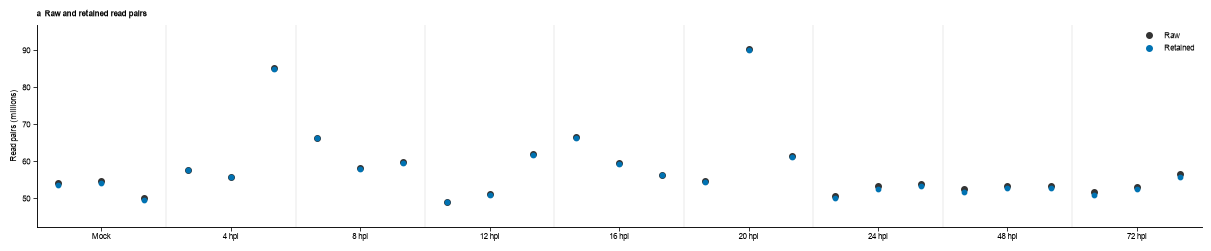

In [4]:
preview,ax=plt.subplots(figsize=(12,2.4),layout="constrained")
plot_panel_a(ax,panel_a,A_STYLE)
plt.show()


## Panel b: fastp quality

Four tracks retain distinct definitions: Q30 and GC after filtering, reported duplication rate, and adapter-trimmed raw reads.


In [5]:
def prepare_panel_b(records):
    rows=[]
    for sample,rec in records.items():
        before=rec["summary"]["before_filtering"]; after=rec["summary"]["after_filtering"]
        rows.append({"sample_id":sample,"q30_percent":100*float(after["q30_rate"]),
          "gc_percent":100*float(after["gc_content"]),
          "duplication_percent":100*float(rec["duplication"]["rate"]),
          "adapter_trimmed_reads_percent":100*int(rec["adapter_cutting"]["adapter_trimmed_reads"])/int(before["total_reads"])})
    data=align_samples(pd.DataFrame(rows))
    metrics=["q30_percent","gc_percent","duplication_percent","adapter_trimmed_reads_percent"]
    v=data[metrics].to_numpy()
    if not np.isfinite(v).all() or (v<0).any() or (v>100).any(): raise ValueError("Invalid fastp percentage")
    return data
panel_b=prepare_panel_b(fastp)
display(panel_b[["sample_id","q30_percent","gc_percent","duplication_percent","adapter_trimmed_reads_percent"]].head())


,sample_id,q30_percent,gc_percent,duplication_percent,adapter_trimmed_reads_percent
0,Mock_00h_1,96.1374,43.0628,10.97670,1.439569
1,Mock_00h_2,96.4334,43.1442,11.48810,1.340142
2,Mock_00h_3,96.2209,43.0739,10.89330,1.318642
3,Pi_04h_1,97.5613,43.0055,8.40046,2.018555
4,Pi_04h_2,97.9645,43.6586,11.92000,4.101497


In [6]:
B_METRICS=[("q30_percent","Q30 (%)",False,"o","#0072B2"),
           ("gc_percent","GC (%)",False,"s","#009E73"),
           ("duplication_percent","Dup. (%)",True,"v","#D55E00"),
           ("adapter_trimmed_reads_percent","Adapter (%)",True,"D","#CC79A7")]
B_STYLE={"point_size":7,"label_x":-.125}
def plot_panel_b(axes,data,style):
    """Four fastp metrics use distinct shapes and colour-blind-friendly colours."""
    centers,boundaries,times=time_geometry(data); x=np.arange(1,len(data)+1)
    for index,(ax,(column,label,lower_zero,marker,color)) in enumerate(zip(axes,B_METRICS)):
        ax.scatter(x,data[column],s=style["point_size"],color=color,marker=marker,zorder=3)
        draw_boundaries(ax,boundaries); style_axis(ax)
        ax.set_xlim(.5,len(data)+.5); ax.set_ylim(*padded_limits(data[column],lower_zero))
        ax.set_ylabel(label,fontsize=6,labelpad=2)
        ax.yaxis.set_label_coords(style["label_x"],.5)
        if index<3: ax.set_xticks([])
        else: ax.set_xticks(centers,time_labels(times),fontsize=6)
    axes[0].set_title("b  Sequence quality",loc="left",fontsize=6,fontweight="bold",pad=6)
    return axes


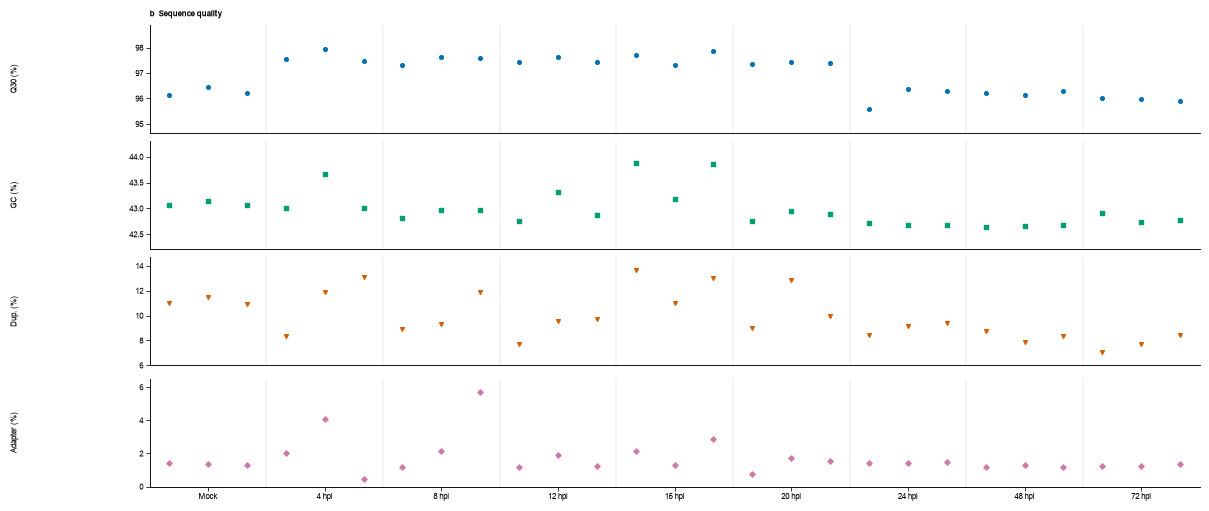

In [7]:
preview,axes=plt.subplots(4,1,figsize=(12,5),layout="constrained")
plot_panel_b(axes,panel_b,B_STYLE)
plt.show()


## Panel c: five-category read assignment

The real assignment table from 05_analysis contains potato nuclear, potato organellar, P. infestans, multimapped and unmapped **read-pair counts**. The five classes are exclusive and sum to the HISAT2 non-rRNA input pairs. Fractions are recomputed from these counts, matching the script's denominator and category order.


In [8]:
CATEGORIES=["potato_nuclear","potato_organellar","p_infestans","multimapped","unmapped"]
def prepare_panel_c(path,mapping_path,hisat_path):
    real=pd.read_csv(path,sep="\t")
    if set(real.data_status)!={"REAL"}: raise ValueError("Panel c requires REAL records")
    numeric=real[CATEGORIES].apply(pd.to_numeric,errors="raise")
    if numeric.isna().any().any() or (numeric<0).any().any() or (numeric%1!=0).any().any():
        raise ValueError("Invalid assignment counts")
    real=align_samples(real)
    mapping=pd.read_csv(mapping_path,sep="\t").set_index("sample")
    hisat=pd.read_csv(hisat_path,sep="\t").set_index("Sample")
    for row in real.itertuples():
        sample=row.sample_id; expected=int(mapping.loc[sample,"input_non_rrna_pairs"])
        if expected!=int(hisat.loc[sample,"paired_total"]) or expected!=sum(getattr(row,x) for x in CATEGORIES):
            raise ValueError(f"Non-rRNA pair categories do not close: {sample}")
        if row.potato_nuclear!=int(mapping.loc[sample,"Stu_nuclear_pairs"]) or row.potato_organellar!=int(mapping.loc[sample,"MtPt_pairs"]):
            raise ValueError(f"Potato assignment mismatch: {sample}")
        if row.multimapped!=int(hisat.loc[sample,"paired_aligned_multi"]) or row.unmapped!=int(hisat.loc[sample,"paired_aligned_none"]):
            raise ValueError(f"HISAT2 assignment mismatch: {sample}")
    real["input_non_rrna_pairs"]=real[CATEGORIES].sum(axis=1)
    for name in CATEGORIES: real[name+"_fraction"]=real[name]/real.input_non_rrna_pairs
    return real
panel_c=prepare_panel_c(INPUT/"fig2c.assignment_real.tsv",INPUT/"fig2c.mapping_composition.tsv",INPUT/"fig2c.multiqc_hisat2.txt")
display(panel_c[["sample_id","input_non_rrna_pairs",*CATEGORIES]].head())


,sample_id,input_non_rrna_pairs,potato_nuclear,potato_organellar,p_infestans,multimapped,unmapped
0,Mock_00h_1,53115439,44364195,5436,4,1877260,6868544
1,Mock_00h_2,53584190,44831943,5169,3,1938170,6808905
2,Mock_00h_3,49113530,40957861,5155,0,1743897,6406617
3,Pi_04h_1,57117744,47367992,7487,97655,1704265,7940345
4,Pi_04h_2,54657477,45909292,9081,108204,1677504,6953396


In [9]:
C_STYLE={"colors":{"potato_nuclear":"#0072B2","potato_organellar":"#CC79A7","p_infestans":"#E69F00","multimapped":"#56B4E9","unmapped":"#666666"},
         "labels":{"potato_nuclear":"Potato nuclear","potato_organellar":"Potato organellar","p_infestans":r"$P.$ $infestans$","multimapped":"Multimapped","unmapped":"Unmapped"}}
def plot_panel_c(ax,data,style):
    """Exclusive read-pair categories over the non-rRNA pair denominator."""
    centers,boundaries,times=time_geometry(data)
    x=np.arange(1,len(data)+1); bottom=np.zeros(len(data))
    for name in CATEGORIES:
        values=data[name+"_fraction"].to_numpy()
        ax.bar(x,values,bottom=bottom,width=.90,color=style["colors"][name],edgecolor="none",zorder=2)
        bottom+=values
    draw_boundaries(ax,boundaries); style_axis(ax)
    ax.set_xlim(0.5,len(data)+0.5); ax.set_ylim(0,1); ax.set_yticks([0,.25,.5,.75,1])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value,_:f"{value*100:.0f}"))
    ax.set_ylabel("Read assignment (%)",fontsize=6,labelpad=3)
    ax.set_xlabel("Libraries",fontsize=6,labelpad=3)
    ax.set_xticks(centers,time_labels(times),fontsize=6)
    ax.set_title("c  Read assignment",loc="left",fontsize=6,fontweight="bold",pad=31)
    ax.legend(handles=[Patch(facecolor=style["colors"][name],label=style["labels"][name]) for name in CATEGORIES],
              frameon=False,ncol=3,fontsize=6,handlelength=.9,columnspacing=.8,
              loc="lower left",bbox_to_anchor=(0,1.02))
    return ax


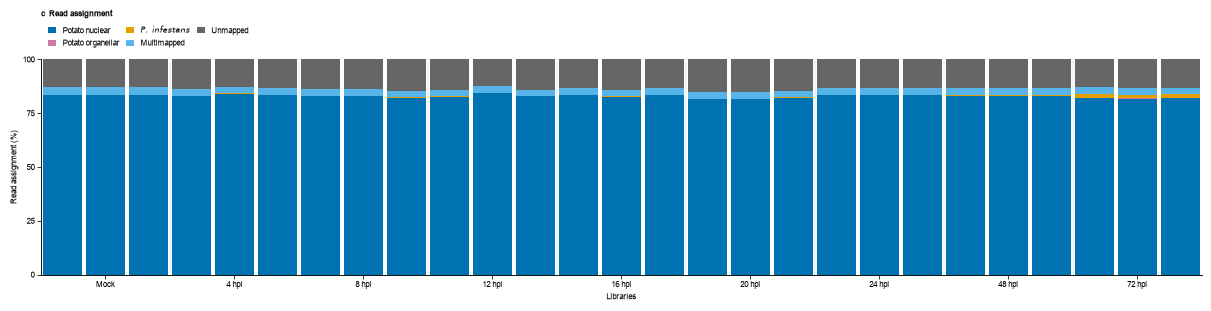

In [10]:
preview,ax=plt.subplots(figsize=(12,3),layout="constrained")
plot_panel_c(ax,panel_c,C_STYLE)
plt.show()


## Panel d: host quantification by sampling time

For each time group, the left side displays the mean and full observed range of featureCounts Assigned fragment percentages, plus all three library values. The percentage denominator is uniquely assigned potato nuclear read pairs from panel c, and the numerator comes from paired-fragment featureCounts. The right side displays a horizontal boxplot and all three library counts for potato genes detected at TPM > 1. The time-group labels form the central y-axis. These descriptive ranges are not confidence intervals.


In [11]:
def prepare_panel_d(path,assignment):
    host=pd.read_csv(path,sep="\t")
    if set(host.data_status)!={"REAL"} or set(host.detection_criterion)!={"TPM > 1"}:
        raise ValueError("Panel d requires real TPM > 1 records")
    fields=["feature_assigned_fragments","detected_genes_tpm_gt_1"]
    host[fields]=host[fields].apply(pd.to_numeric,errors="raise")
    if host[fields].isna().any().any() or (host[fields]<=0).any().any() or (host[fields]%1!=0).any().any():
        raise ValueError("Invalid host assignment/detection counts")
    host=align_samples(host)
    nuclear=assignment.set_index("sample_id").loc[host.sample_id,"potato_nuclear"].to_numpy(dtype=np.int64)
    if (nuclear<=0).any() or (host.feature_assigned_fragments.to_numpy()>nuclear).any():
        raise ValueError("Assigned fragments exceed uniquely assigned potato nuclear pairs")
    host["potato_nuclear_pairs"]=nuclear
    host["feature_assigned_percent"]=100*host.feature_assigned_fragments/host.potato_nuclear_pairs
    return host
panel_d=prepare_panel_d(INPUT/"fig2d.host_assignment_real.tsv",panel_c)
display(panel_d[["sample_id","feature_assigned_fragments","potato_nuclear_pairs","feature_assigned_percent","detected_genes_tpm_gt_1"]].head())


,sample_id,feature_assigned_fragments,potato_nuclear_pairs,feature_assigned_percent,detected_genes_tpm_gt_1
0,Mock_00h_1,37440881,44364195,84.394366,16901
1,Mock_00h_2,37805589,44831943,84.327349,16908
2,Mock_00h_3,34710065,40957861,84.745795,16876
3,Pi_04h_1,40469519,47367992,85.436425,17323
4,Pi_04h_2,39511812,45909292,86.064956,16839


In [12]:
D_STYLE={"box":"#56B4E9","summary":"#0072B2","points":"#333333"}
def plot_panel_d(axes,data,style):
    """Two-sided horizontal summaries with shared time rows and raw replicates."""
    left,middle,right=axes
    times=sorted(data.time_h.unique()); positions=np.arange(1,len(times)+1)
    gene_groups=[data.loc[data.time_h==time,"detected_genes_tpm_gt_1"].to_numpy() for time in times]
    rate_groups=[data.loc[data.time_h==time,"feature_assigned_percent"].to_numpy() for time in times]
    if any(len(a)!=3 or len(b)!=3 for a,b in zip(gene_groups,rate_groups)):
        raise ValueError("Expected three libraries per time")
    right.boxplot(gene_groups,orientation="horizontal",positions=positions,widths=.43,
                 patch_artist=True,showfliers=False,manage_ticks=False,
                 boxprops={"facecolor":style["box"],"alpha":.45,"edgecolor":style["summary"],"linewidth":.65},
                 medianprops={"color":style["points"],"linewidth":.65},
                 whiskerprops={"color":style["summary"],"linewidth":.65},
                 capprops={"color":style["summary"],"linewidth":.65})
    for y,values in zip(positions,gene_groups):
        right.scatter(values,y+np.array([-.11,0,.11]),s=5,color=style["points"],zorder=3)
    for y,values in zip(positions,rate_groups):
        mean=float(np.mean(values)); low=float(np.min(values)); high=float(np.max(values))
        left.errorbar(mean,y,xerr=[[mean-low],[high-mean]],fmt="o",markersize=3.3,
                      color=style["summary"],elinewidth=.7,capsize=2,capthick=.7,zorder=2)
        left.scatter(values,y+np.array([-.11,0,.11]),s=5,color=style["points"],zorder=3)
    for ax in (left,right):
        style_axis(ax); ax.set_ylim(len(times)+.5,.5)
        ax.set_yticks([]); ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.grid(axis="x",color="#D2D2D2",linewidth=.35,zorder=0)
    left.spines["left"].set_visible(False)
    left.spines["right"].set_visible(True)
    left.spines["right"].set_linewidth(.65)
    left.yaxis.tick_right()
    genes=np.concatenate(gene_groups); rates=np.concatenate(rate_groups)
    rate_lo,rate_hi=padded_limits(rates,lower_zero=True)
    left.set_xlim(rate_hi,rate_lo)
    right.set_xlim(*padded_limits(genes))
    right.xaxis.set_major_formatter(FuncFormatter(lambda value,_:f"{value/1000:.1f}k"))
    left.set_xlabel("Feature-assigned fragments (%)",fontsize=6,labelpad=3)
    right.set_xlabel("Detected genes (TPM > 1)",fontsize=6,labelpad=3)
    middle.set_xlim(0,1); middle.set_ylim(len(times)+.5,.5); middle.axis("off")
    for y,label in zip(positions,time_labels(times)):
        middle.text(.5,y,label,ha="center",va="center",fontsize=6)
    left.set_title("d  Host quantification",loc="left",fontsize=6,fontweight="bold",pad=31)
    return axes


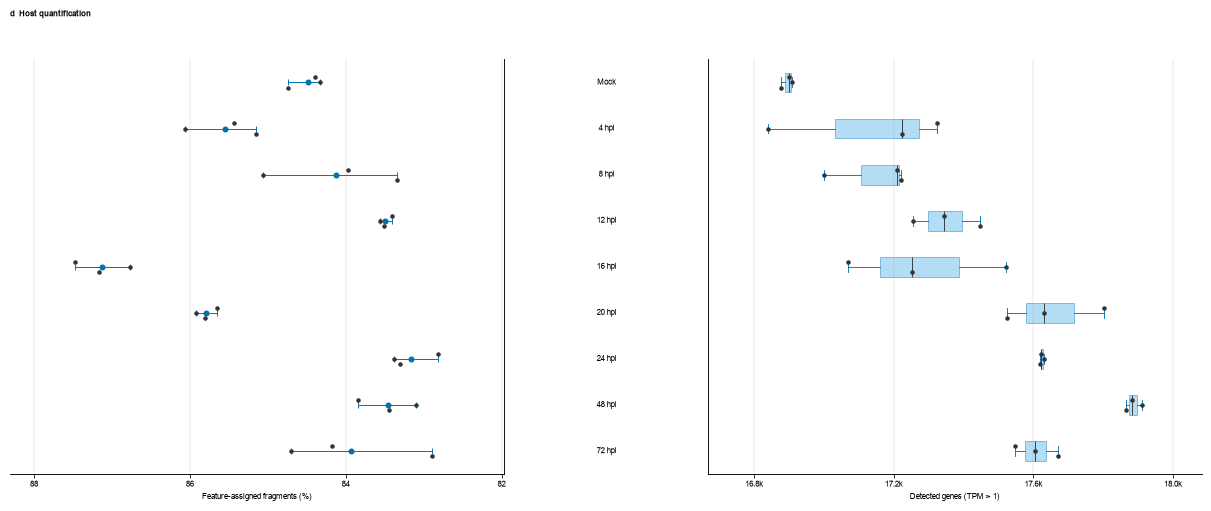

In [13]:
preview=plt.figure(figsize=(12,5),layout="constrained")
sub=preview.add_gridspec(1,3,width_ratios=[1,.28,1],wspace=.08)
axes=[preview.add_subplot(sub[0,i]) for i in range(3)]
plot_panel_d(axes,panel_d,D_STYLE)
plt.show()


## Assemble and export Figure 2

The same prepared data objects feed the previews, final figure and source-data tables. Panel a shows raw and retained read-pair counts. Panel c retains its five-category, non-rRNA pair denominator. Panel d groups the 27 libraries into nine rows of three replicates, with assignment percentages left, detected-gene counts right, and time labels between them. The y-axis of the left percentage plot is on its right edge. For a manuscript figure legend, identify panels a and b as saved fastp metrics from MultiQC 1.35 and state that no review thresholds were added; provenance details are kept outside the graphic.


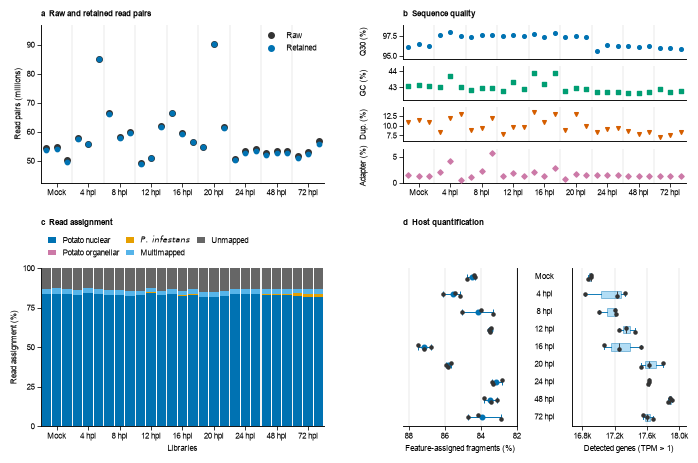

In [14]:
fig=plt.figure(figsize=STYLE["figure_size"],facecolor="white")
outer=fig.add_gridspec(2,2,width_ratios=[1,1],height_ratios=[1,1],
    left=.07,right=.98,top=.95,bottom=.10,wspace=.28,hspace=.54)
ax_a=fig.add_subplot(outer[0,0])
sub_b=outer[0,1].subgridspec(4,1,hspace=.22)
axes_b=[fig.add_subplot(sub_b[i,0]) for i in range(4)]
ax_c=fig.add_subplot(outer[1,0])
sub_d=outer[1,1].subgridspec(1,3,width_ratios=[1,.35,1],wspace=.08)
axes_d=[fig.add_subplot(sub_d[0,i]) for i in range(3)]
plot_panel_a(ax_a,panel_a,A_STYLE); plot_panel_b(axes_b,panel_b,B_STYLE)
plot_panel_c(ax_c,panel_c,C_STYLE); plot_panel_d(axes_d,panel_d,D_STYLE)
plt.show()


In [15]:
outdir=FIGURES/"output"/"fig2"; source_dir=outdir/"source_data"
source_dir.mkdir(parents=True,exist_ok=True)
fig.savefig(outdir/"Fig2.png",dpi=STYLE["png_dpi"],facecolor="white")
try:
    fig.savefig(outdir/"Fig2.pdf",facecolor="white")
except PermissionError:
    fig.savefig(outdir/"Fig2_updated.pdf",facecolor="white")
    print("Fig2.pdf is open in another application; saved Fig2_updated.pdf")
panel_a[["sample_id","time_h","biological_replicate","raw_read_pairs","retained_read_pairs","retained_percent","filtered_out_percent"]].to_csv(source_dir/"Fig2a_read_counts.tsv",sep="\t",index=False,float_format="%.17g",lineterminator="\n")
panel_b[["sample_id","time_h","biological_replicate",*[x[0] for x in B_METRICS]]].to_csv(source_dir/"Fig2b_quality_metrics.tsv",sep="\t",index=False,float_format="%.17g",lineterminator="\n")
panel_c[["sample_id","time_h","biological_replicate","input_non_rrna_pairs",*CATEGORIES,*[x+"_fraction" for x in CATEGORIES]]].to_csv(source_dir/"Fig2c_mapping_composition.tsv",sep="\t",index=False,float_format="%.17g",lineterminator="\n")
panel_d[["sample_id","time_h","biological_replicate","feature_assigned_fragments","potato_nuclear_pairs","feature_assigned_percent","detected_genes_tpm_gt_1","data_status","detection_criterion"]].to_csv(source_dir/"Fig2d_host_assignment.tsv",sep="\t",index=False,float_format="%.17g",lineterminator="\n")
print(f"Exported {outdir}")


Exported C:\Users\Txieb\Desktop\RNA-seq_PotatoPi_Release\figures\output\fig2
